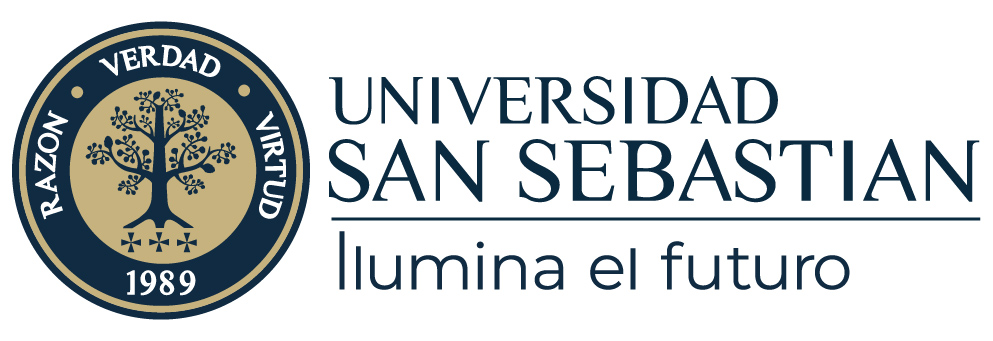

# **INFORME SOLEMNE 2** 
## Maratón olímpica: evolución histórica y caso Manuel Plaza 

Autores: Karina Barrientos, Lucas Brown Ibieta y Vincent Bustamante

RUTs: ??-???-???-?, 21.063.252-2, ??-???-???-?

Docente: Israel Naranjo Retamal

Asignatura: TALLER DE TATA SCIENCE Y BIG DATA

Fecha: 06/11/2026

<a id="indice-contenidos"></a>
## **ÍNDICE DE CONTENIDOS**

**ENTENDIMIENTO DEL PROYECTO**

1. [Contexto y justificación del análisis](#contexto-proyecto)
2. [Objetivos y criterios de éxito](#objetivos-proyecto)
3. [Alcance, fuentes y reproducción](#alcance-proyecto)
4. [Preparación del entorno de trabajo](#preparacion-entorno)

**MACROANÁLISIS Y EVOLUCIÓN HISTÓRICA DEL MARATÓN OLÍMPICO — SECCIÓN I**

1. [Ingesta, limpieza y filtrado de la prueba](#tarea-1)
2. [Extracción de los podios históricos](#tarea-2)
3. [Visualización y análisis de la evolución temporal](#tarea-3)

**PROFUNDIZACIÓN HISTÓRICA: MANUEL PLAZA EN ÁMSTERDAM 1928 — SECCIÓN II**

4. [Podio de 1928 y diferencia exacta respecto del oro](#tarea-4)
5. [Simulación de integración con fuentes documentales](#tarea-5)
6. [Procesamiento de lenguaje natural sobre las crónicas](#tarea-6)
7. [Síntesis automatizada: de los datos a la crónica](#tarea-7)

**PREGUNTA CONCEPTUAL Y DE CIERRE — SECCIÓN III**

8. [Reflexión crítica sobre Big Data e historia](#tarea-8)

**CIERRE DEL INFORME**

- [Conclusiones integradas](#conclusiones-integradas)
- [Fuentes documentales y límites del trabajo](#fuentes-limites)

---


<a id="contexto-proyecto"></a>
## **Entendimiento del proyecto**

### 1. Contexto y justificación del análisis

Un tiempo de llegada permite ordenar una competencia, pero no explica la vida de
quien lo consiguió. Este proyecto aborda esa diferencia mediante dos escalas de
observación: primero examina la maratón masculina en las ediciones olímpicas
disponibles y luego se concentra en la plata de Manuel Plaza en Ámsterdam 1928.
La primera escala permite reconocer cambios en los registros ganadores; la segunda
vincula una diferencia deportiva concreta con lugares, oficios y relatos documentales.

La integración se organiza a partir de cuatro tablas de Kaggle: resultados,
medallas, sedes y fichas de atletas. Los resultados aportan clasificación y marcas;
las sedes permiten asignar año y ciudad; las medallas sirven para contrastar el
podio; las fichas añaden información biográfica cuando existe una correspondencia.
Después se incorpora un pequeño corpus para mostrar cómo el NLP puede organizar
contexto que no está representado en las columnas deportivas.

<a id="objetivos-proyecto"></a>
### 2. Objetivos de Data Science y criterios de éxito

| Objetivo | Evidencia con la que se comprueba |
|---|---|
| Seleccionar exclusivamente la maratón masculina de atletismo | Filtro por disciplina y nombre exacto de la prueba, con balance de filas |
| Comparar marcas registradas en formatos distintos | Conversión explícita a segundos y conservación de las fracciones históricas |
| Reconstruir el podio de cada edición disponible | Una medalla de cada tipo por edición y contraste entre results y medals |
| Explicar la evolución del oro | Gráfico, diferencias entre ediciones y análisis con límites de comparabilidad |
| Medir el resultado de Manuel Plaza | Podio de 1928 y cálculo reproducible de la brecha respecto del primer lugar |
| Relacionar estadística y contexto humano | Entidades, evidencias léxicas y una crónica con procedencia documental |

El criterio de calidad es que cada cifra pueda rastrearse hasta una transformación
de los CSV y cada afirmación de contexto tenga una fuente identificada. Las
recreaciones del ejercicio se reconocen como simulaciones durante todo el proceso.

<a id="alcance-proyecto"></a>
### 3. Alcance, fuentes y reproducción

La copia local contiene información de verano e invierno hasta 2022; la serie de
maratón masculina termina en **Tokio 2020**, celebrado en 2021. No se incorporan
resultados de París 2024. La columna Ciudad representa la sede de la edición;
en Tokio 2020, por ejemplo, no identifica el lugar efectivo del circuito de maratón.

Los cuatro CSV se encuentran en `SetDatos/`. La carpeta `datos_documentales/`
contiene las paráfrasis con procedencia y el suplemento de tres marcas de Tokio,
ausentes en el CSV original. El análisis guarda sus derivados en `resultados/`.
El notebook incluye el código de las ocho tareas: puede ejecutarse sin abrir los
archivos Python individuales, siempre que se conserven las dos carpetas de datos.

Para reproducirlo, seleccionar el entorno Python con las dependencias de
`requirements.txt` y ejecutar las celdas desde el principio. No se necesita conexión
durante el análisis ni descargar un modelo lingüístico. Los scripts separados
permiten reutilizar las funciones y el generador mantiene este informe sincronizado.

[Volver al índice](#indice-contenidos)


<a id="preparacion-entorno"></a>
## **Preparación del entorno de trabajo**

La primera celda configura la presentación del informe. `Path` permite construir
rutas sin escribir separadores específicos del sistema operativo; `tempfile`
localiza una carpeta temporal en la que Matplotlib puede guardar su configuración.
Esto evita depender de permisos de escritura en la carpeta personal del usuario.

La instrucción `run_line_magic("matplotlib", "inline")` hace que las figuras
aparezcan dentro del notebook. Su ejecución se condiciona a la presencia de IPython,
por lo que no se presupone que este mecanismo exista en una consola Python común.
Finalmente, las opciones de pandas permiten mostrar hasta 12 columnas y 100 filas:
ese límite basta para examinar los 87 medallistas sin truncar el listado de filas.
Esta celda prepara la visualización; todavía no carga ni transforma los datos.


In [1]:
import os
import tempfile
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "u2-matplotlib"))
if "get_ipython" in globals():
    get_ipython().run_line_magic("matplotlib", "inline")
import pandas as pd
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 100)

La ausencia de una tabla en esta salida es esperada: se han configurado
opciones, no ejecutado consultas sobre los CSV. En las siguientes celdas, pandas
se utilizará para tablas y uniones, NumPy para operaciones numéricas, Matplotlib
para figuras y spaCy para el procesamiento de texto en español. Las versiones de
la ejecución verificada se registran en `resultados/verificacion_ejecucion.json`.


# **SECCIÓN I · Macroanálisis y evolución histórica del maratón olímpico**

<a id="tarea-1"></a>
## **1. Ingesta, limpieza y filtrado de la prueba**

La preparación define qué observaciones se pueden comparar. Primero se establece una ruta reproducible y se inspecciona la estructura de las cuatro fuentes; después se selecciona la prueba y se normalizan las marcas. Los registros descartados se conservan con una explicación para distinguir problemas deportivos de problemas de información.

### 1.1. Bibliotecas y localización de los archivos

Se importan las herramientas generales y se define `localizar_proyecto()`. La
función busca la carpeta que contiene `SetDatos/olympic_results.csv`; encontrar ese
archivo permite fijar `BASE` sin introducir una ruta personal en cada lectura.
`SALIDA` se construye a partir de esa base y `mkdir(exist_ok=True)` permite volver
a ejecutar el informe aunque `resultados/` ya exista.

Esta separación de rutas tiene una finalidad práctica: los originales se leen
desde una carpeta y los productos del análisis se escriben en otra. En esta celda
solo se definen herramientas y ubicaciones; la lectura de los CSV se realizará
cuando se llame a `cargar_datos()`.


In [2]:
from pathlib import Path

from datetime import timedelta

import hashlib

import json

import re

import unicodedata

import numpy as np

import pandas as pd

def localizar_proyecto():
    """Localiza el proyecto desde su carpeta, U2, U1 o al ejecutar un módulo."""
    candidatos = [Path.cwd(), Path.cwd() / "U2", Path.cwd().parent / "U2",
                  Path.cwd() / "olympic_marathon_analysis",
                  Path.cwd() / "U2" / "olympic_marathon_analysis",
                  Path.cwd().parent / "U2" / "olympic_marathon_analysis"]
    if "__file__" in globals():
        candidatos.insert(0, Path(__file__).resolve().parent.parent)
    for candidato in candidatos:
        if (candidato / "SetDatos" / "olympic_results.csv").is_file():
            return candidato.resolve()
    raise FileNotFoundError("Abra el notebook desde olympic_marathon_analysis, junto a SetDatos/.")

BASE = localizar_proyecto()

SALIDA = BASE / "resultados"

SALIDA.mkdir(exist_ok=True)

### 1.2. Normalización de etiquetas y filtro de la maratón masculina

Los textos que identifican una misma prueba pueden variar en mayúsculas,
tildes o espacios. `normalizar_texto()` homogeneiza esas diferencias para comparar
etiquetas, sin reemplazar los nombres originales que se presentarán en las tablas.

`mascara_maraton()` combina dos condiciones con `&`: la disciplina debe ser
Athletics y el evento debe coincidir exactamente con `marathon men` o `men's
marathon`. Usar únicamente una búsqueda de la palabra marathon incluiría pruebas
de natación en aguas abiertas y otras categorías. La función devuelve una máscara
booleana que luego se aplica con `.loc[...]`.


In [3]:
def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", str(texto).casefold())
    return " ".join("".join(c for c in texto if not unicodedata.combining(c)).split())

def mascara_maraton(df):
    return (
        df["discipline_title"].map(normalizar_texto).eq("athletics")
        & df["event_title"].map(normalizar_texto).isin(["marathon men", "men's marathon"])
    )

### 1.3. Lectura de las cuatro fuentes y validación del esquema

`pd.read_csv(..., dtype="string")` carga los archivos conservando las etiquetas,
los identificadores y las marcas originales como texto. La conversión a números
se reserva para las variables que realmente lo requieren, como año y tiempo.
Cada tabla se guarda en un diccionario con una clave que identifica su función.

Antes de continuar se comprueba que existan las columnas requeridas. Si una copia
del dataset cambia de esquema, se produce un error explícito en lugar de obtener
silenciosamente una tabla parcial. Esta comprobación valida la estructura; no
garantiza todavía que cada fila esté completa o que los identificadores sean únicos.


In [4]:
def cargar_datos(carpeta=None):
    carpeta = Path(carpeta) if carpeta else BASE / "SetDatos"
    tablas = {
        nombre: pd.read_csv(carpeta / f"olympic_{nombre}.csv", dtype="string")
        for nombre in ("athletes", "results", "hosts", "medals")
    }
    requeridas = {
        "results": {"discipline_title", "event_title", "slug_game", "athlete_url",
                    "athlete_full_name", "country_name", "country_3_letter_code",
                    "rank_position", "medal_type", "value_unit", "value_type"},
        "hosts": {"game_slug", "game_year", "game_name", "game_start_date", "game_season"},
        "athletes": {"athlete_url", "athlete_full_name", "athlete_year_birth"},
        "medals": {"discipline_title", "event_title", "slug_game", "medal_type",
                   "athlete_full_name", "country_3_letter_code"},
    }
    for nombre, columnas in requeridas.items():
        faltan = columnas - set(tablas[nombre])
        if faltan:
            raise ValueError(f"{nombre}: faltan columnas {sorted(faltan)}")
    return tablas

### 1.4. Conversión de marcas a segundos y formato de presentación

La comparación temporal exige una unidad común. En esta copia, los valores
numéricos de `value_unit` están expresados en **milisegundos**, por lo que se dividen
por 1000. Por ejemplo, la marca de Plaza se interpreta como
**9 203 000 ms ÷ 1000 = 9203 s = 02:33:23**. `value_type=TIME` identifica el tipo
de resultado, pero no basta por sí solo para declarar su escala.

`normalizar_tiempo()` también acepta cadenas HH:MM:SS, fracciones de segundo y
objetos timedelta. La expresión regular valida la forma de la cadena y se revisa
que minutos y segundos sean menores que 60. Valores como DNF, DNS o DSQ, marcas
vacías y formatos no interpretables devuelven `NaN`: no se convierten en cero.
La unidad numérica se recibe como parámetro, evitando inferirla por la magnitud.

`formatear_tiempo()` vuelve a una representación legible sin perder décimas
históricas. La última función, `mostrar_tabla()`, elige una tabla HTML en Jupyter
o una representación de texto al ejecutar los scripts desde consola.


In [5]:
def normalizar_tiempo(valor, unidad_numerica="ms"):
    """Devuelve segundos o NaN; numéricos en ms (dataset) o s, sin adivinar."""
    if unidad_numerica not in {"ms", "s"}:
        raise ValueError("unidad_numerica debe ser 'ms' o 's'")
    if valor is None or pd.isna(valor):
        return np.nan
    if isinstance(valor, (pd.Timedelta, timedelta)):
        segundos = valor.total_seconds()
    else:
        texto = str(valor).strip().upper().replace(",", ".")
        if texto in {"", "DNF", "DNS", "DSQ", "DQ", "DQB", "NM", "N/A", "NAN", "-"}:
            return np.nan
        if re.fullmatch(r"\d+(?:\.\d+)?", texto):
            segundos = float(texto) / (1000 if unidad_numerica == "ms" else 1)
        else:
            texto = re.sub(r"\s+", "", texto)
            texto = re.sub(r"H|M", ":", texto).removesuffix("S")
            texto = re.sub(r"^(\d+)-(\d{2}:)", r"\1:\2", texto)
            match = re.fullmatch(r"(\d{1,2}):(\d{2}):(\d{2}(?:\.\d+)?)", texto)
            if not match:
                return np.nan
            horas, minutos, seg = map(float, match.groups())
            if minutos >= 60 or seg >= 60:
                return np.nan
            segundos = horas * 3600 + minutos * 60 + seg
    return round(float(segundos), 6) if np.isfinite(segundos) and segundos > 0 else np.nan

def formatear_tiempo(segundos):
    """HH:MM:SS.mmm sin perder décimas históricas; vacío si no hay marca."""
    if pd.isna(segundos):
        return "Sin marca"
    milisegundos = round(float(segundos) * 1000)
    horas, resto = divmod(milisegundos, 3_600_000)
    minutos, resto = divmod(resto, 60_000)
    seg, fraccion = divmod(resto, 1000)
    sufijo = f".{fraccion:03d}".rstrip("0") if fraccion else ""
    return f"{horas:02d}:{minutos:02d}:{seg:02d}{sufijo}"

def mostrar_tabla(tabla):
    """Tabla HTML en Jupyter; texto legible al ejecutar los archivos Python."""
    try:
        from IPython import get_ipython
        from IPython.display import display
        if get_ipython() is not None:
            display(tabla)
            return
    except ImportError:
        pass
    print(tabla.to_string(index=False))

### 1.5. Integración de tablas y auditoría de las exclusiones

La limpieza comienza con el filtro de la prueba y la eliminación de filas
exactamente repetidas. Después se añade la información de sedes mediante
`merge(..., validate="many_to_one")`: varios resultados pueden pertenecer a una
misma edición, pero cada clave de edición debe corresponder a una sola sede.
El indicador de la unión permite detectar resultados sin correspondencia.

El cruce con atletas utiliza URL no nulas y limita las fichas a quienes participan
en la prueba. Así se evitan uniones entre nulos y multiplicaciones de filas por
identificadores repetidos. La falta de una ficha biográfica no elimina un resultado
deportivo que tenga nombre, clasificación y tiempo válidos.

Luego se distinguen el año nominal, el año de celebración, la ciudad y las marcas
originales y normalizadas. `np.select()` asigna un motivo de exclusión: estado sin
clasificación válida o marca ausente/no interpretable. La función devuelve la
tabla filtrada completa, los registros utilizables, los excluidos y un resumen
de auditoría. El balance entre esas salidas impide perder filas sin explicación.


In [6]:
def limpiar_maraton(tablas):
    originales = tablas["results"].loc[mascara_maraton(tablas["results"])].copy()
    df = originales.drop_duplicates().copy()
    hosts = tablas["hosts"].rename(columns={"game_slug": "slug_game"})
    df = df.merge(hosts, on="slug_game", how="left", validate="many_to_one", indicator=True)
    if not df["_merge"].eq("both").all() or not df["game_season"].eq("Summer").all():
        raise ValueError("Hay resultados sin sede o fuera de Juegos de Verano")
    df = df.drop(columns="_merge")
    # Solo identificadores no nulos: pandas puede unir nulos entre sí.
    atletas = tablas["athletes"].dropna(subset=["athlete_url"])
    atletas = atletas.loc[atletas["athlete_url"].isin(df["athlete_url"].dropna())]
    # Se aceptan duplicados exactos; los identificadores contradictorios fallan.
    atletas = atletas.drop_duplicates()
    if atletas["athlete_url"].duplicated().any():
        raise ValueError("Identificadores de atletas con fichas contradictorias")
    atletas = atletas.rename(columns={"athlete_full_name": "nombre_ficha"})
    df = df.merge(atletas[["athlete_url", "nombre_ficha", "athlete_year_birth"]],
                  on="athlete_url", how="left", validate="many_to_one")
    df["athlete_full_name"] = df["athlete_full_name"].fillna(df["nombre_ficha"])
    df["Año"] = pd.to_numeric(df["game_year"], errors="raise").astype(int)
    df["Año celebración"] = pd.to_datetime(df["game_start_date"], utc=True).dt.year
    df["Ciudad"] = df["game_name"].str.replace(r"\s+\d{4}$", "", regex=True)
    df["Tiempo original"] = df["value_unit"]
    df["Tiempo segundos"] = df["value_unit"].map(normalizar_tiempo)
    df["Tiempo"] = df["Tiempo segundos"].map(formatear_tiempo)
    df["Tiempo timedelta"] = pd.to_timedelta(df["Tiempo segundos"], unit="s")
    rango = pd.to_numeric(df["rank_position"], errors="coerce")
    estado_invalido = rango.isna() | df["value_type"].eq("IRM").fillna(False)
    df["Motivo exclusión"] = np.select(
        [estado_invalido.to_numpy(dtype=bool), df["Tiempo segundos"].isna()],
        ["Estado sin clasificación válida (DNF/DNS/DSQ/IRM)", "Marca ausente o formato inválido"],
        default="",
    )
    validos = df.loc[df["Motivo exclusión"].eq("")].copy()
    excluidos = df.loc[df["Motivo exclusión"].ne("")].copy()
    auditoria = {
        "filas_fuentes": {k: len(v) for k, v in tablas.items()},
        "registros_maraton_originales": len(originales),
        "duplicados_exactos_eliminados": len(originales) - len(df),
        "ediciones_maraton": int(df["slug_game"].nunique()),
        "primer_anio": int(df["Año"].min()), "ultimo_anio_edicion": int(df["Año"].max()),
        "marcas_validas_originales": len(validos), "registros_excluidos": len(excluidos),
        "motivos": excluidos["Motivo exclusión"].value_counts().to_dict(),
        "sin_ficha_atleta": int(df["nombre_ficha"].isna().sum()),
        "urls_atletas_duplicadas_fuente_global": int(tablas["athletes"]["athlete_url"].duplicated().sum()),
        "unidad_numerica": "milisegundos", "division_a_segundos": 1000,
    }
    if len(validos) + len(excluidos) != len(df):
        raise AssertionError("La auditoría no conserva el total de filas")
    return df, validos, excluidos, auditoria

### 1.6. Ejecución de la ingesta y revisión de los resultados

Ahora se llaman las funciones anteriores. `cargar_datos()` entrega las cuatro
fuentes y `limpiar_maraton()` devuelve los objetos que usarán las tareas siguientes.
Las tablas limpia y excluida se exportan por separado; la auditoría JSON conserva
los tamaños, la cobertura y los motivos de descarte.

También se calcula una huella SHA-256 de cada CSV. Esa huella permite comprobar
si dos ejecuciones usaron exactamente los mismos bytes, aunque no certifica la
veracidad histórica de su contenido. La salida muestra el resumen y cinco ejemplos
de conversión para revisar visualmente la relación entre marca original y segundos.


In [7]:
tablas = cargar_datos()
maraton, maraton_limpia, exclusiones, auditoria = limpiar_maraton(tablas)
maraton_limpia.to_csv(SALIDA / "maraton_limpia.csv", index=False)
exclusiones.to_csv(SALIDA / "registros_excluidos.csv", index=False)
(SALIDA / "auditoria_ingesta.json").write_text(json.dumps(auditoria, indent=2, ensure_ascii=False), encoding="utf-8")
hashes_fuentes = {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in (BASE / "SetDatos").glob("*.csv")}
(SALIDA / "sha256_datasets.json").write_text(json.dumps(hashes_fuentes, indent=2), encoding="utf-8")
print(json.dumps(auditoria, indent=2, ensure_ascii=False))
mostrar_tabla(maraton_limpia[["Año", "athlete_full_name", "Tiempo original", "Tiempo segundos", "Tiempo"]].head())

{
  "filas_fuentes": {
    "athletes": 75904,
    "results": 162804,
    "hosts": 53,
    "medals": 21697
  },
  "registros_maraton_originales": 2296,
  "duplicados_exactos_eliminados": 0,
  "ediciones_maraton": 29,
  "primer_anio": 1896,
  "ultimo_anio_edicion": 2020,
  "marcas_validas_originales": 1560,
  "registros_excluidos": 736,
  "motivos": {
    "Estado sin clasificación válida (DNF/DNS/DSQ/IRM)": 641,
    "Marca ausente o formato inválido": 95
  },
  "sin_ficha_atleta": 367,
  "urls_atletas_duplicadas_fuente_global": 4,
  "unidad_numerica": "milisegundos",
  "division_a_segundos": 1000
}


,Año,athlete_full_name,Tiempo original,Tiempo segundos,Tiempo
106,2016,Eliud KIPCHOGE,7724000,7724.0,02:08:44
107,2016,Feyisa LILESA,7794000,7794.0,02:09:54
108,2016,Galen RUPP,7805000,7805.0,02:10:05
109,2016,Ghirmay GHEBRESLASSIE,7864000,7864.0,02:11:04
110,2016,Alphonce Felix SIMBU,7875000,7875.0,02:11:15


**Interpretación de la auditoría.** Los 162 804 resultados globales se reducen a
2296 registros de maratón masculina distribuidos en 29 ediciones. Se conservan
1560 registros con marca y clasificación válidas; 736 quedan en la tabla de
exclusiones: 641 por estado deportivo y 95 por ausencia o formato de marca.

No hay duplicados exactos entre los resultados seleccionados. Además, 367
registros no encuentran ficha en athletes; se mantienen porque una biografía
ausente no invalida el resultado. La cobertura de marcas originales llega a 28
ediciones: la ausencia de tiempos de Tokio exige una decisión documental explícita
en la tarea siguiente. Estos vacíos no deben interpretarse como abandonos.


[Volver al índice](#indice-contenidos)

<a id="tarea-2"></a>
## **2. Extracción de los podios históricos**

El podio se reconstruye a partir de las medallas adjudicadas y se verifica contra una segunda tabla del mismo conjunto. Este paso distingue el orden oficial de una simple ordenación por tiempo y conserva las ediciones con información incompleta.

### 2.1. Selección de medallas, contraste y suplemento documental

Los diccionarios `MEDALLAS` y `PUESTOS` traducen las etiquetas GOLD, SILVER y
BRONZE a una presentación legible. `extraer_podios()` selecciona esas etiquetas
en la tabla completa de maratón: se parte de la medalla adjudicada para conservar
la clasificación oficial, sin recalcularla ordenando tiempos.

La unión con medals usa edición, medalla y código de país; `validate="one_to_one"`
comprueba que cada clave represente un solo medallista en esta prueba. Para
Tokio se permite incorporar un suplemento local, verificado en
[World Athletics](https://worldathletics.org/news/report/tokyo-olympic-games-men-marathon-report).
Antes de completar una marca se contrastan clave y nombre; si el suplemento
contradice una marca original existente, la función detiene el proceso.

`Tiempo original` conserva la ausencia del CSV y `Complemento documental` identifica
las filas completadas. Finalmente se revisa que cada edición tenga exactamente
un oro, una plata y un bronce, y se ordena por año y posición.


In [8]:
import numpy as np

import pandas as pd

MEDALLAS = {"GOLD": "Oro", "SILVER": "Plata", "BRONZE": "Bronce"}

PUESTOS = {"GOLD": 1, "SILVER": 2, "BRONZE": 3}

COLUMNAS_PODIO = ["Año", "Ciudad", "Puesto (Medalla)", "Atleta", "País/Equipo", "Tiempo"]

def extraer_podios(maraton, tabla_medallas, suplemento=None):
    df = maraton.loc[maraton["medal_type"].isin(MEDALLAS)].copy()
    clave = ["slug_game", "medal_type", "country_3_letter_code"]
    contraste = tabla_medallas.loc[mascara_maraton(tabla_medallas), clave].drop_duplicates()
    control = df.merge(contraste, on=clave, how="outer", indicator=True, validate="one_to_one")
    if not control["_merge"].eq("both").all():
        raise ValueError("Los podios de results y medals no coinciden")
    df["Fuente tiempo"] = "SetDatos/olympic_results.csv (ms)"
    df["Complemento documental"] = False
    if suplemento is not None:
        sup = pd.read_csv(suplemento, dtype="string")
        if sup.duplicated(clave).any():
            raise ValueError("Suplemento con claves duplicadas")
        correspondencia = sup.merge(df[clave], on=clave, how="left", indicator=True, validate="one_to_one")
        if not correspondencia["_merge"].eq("both").all():
            raise ValueError("El suplemento contiene medallistas ajenos al dataset")
        sup = sup.rename(columns={"tiempo": "tiempo_documental", "athlete_full_name": "nombre_documental"})
        df = df.merge(sup[clave + ["nombre_documental", "tiempo_documental", "fuente_url"]],
                      on=clave, how="left", validate="one_to_one")
        documentado = df["tiempo_documental"].notna()
        if not df.loc[documentado, "athlete_full_name"].eq(df.loc[documentado, "nombre_documental"]).all():
            raise ValueError("El nombre documental no coincide con el medallista")
        nuevos = df["tiempo_documental"].map(normalizar_tiempo)
        conflicto = documentado & df["Tiempo segundos"].notna() & ~np.isclose(df["Tiempo segundos"], nuevos, equal_nan=True)
        if conflicto.any():
            raise ValueError("El suplemento contradice una marca original")
        completar = df["Tiempo segundos"].isna() & nuevos.notna()
        df.loc[completar, "Tiempo segundos"] = nuevos.loc[completar]
        df.loc[completar, "Fuente tiempo"] = df.loc[completar, "fuente_url"]
        df.loc[completar, "Complemento documental"] = True
    df["Tiempo"] = df["Tiempo segundos"].map(formatear_tiempo)
    df["Tiempo timedelta"] = pd.to_timedelta(df["Tiempo segundos"], unit="s")
    df["Puesto"] = df["medal_type"].map(PUESTOS)
    df["Medalla"] = df["medal_type"].map(MEDALLAS)
    rango = pd.to_numeric(df["rank_position"], errors="coerce")
    if not rango.eq(df["Puesto"]).all():
        raise ValueError("Posiciones y medallas incompatibles")
    df["Puesto (Medalla)"] = df["Puesto"].astype(str) + " (" + df["Medalla"] + ")"
    df = df.rename(columns={"athlete_full_name": "Atleta", "country_name": "País/Equipo"})
    df = df.sort_values(["Año", "Puesto"]).reset_index(drop=True)
    cobertura = df.groupby("slug_game")["medal_type"].agg(set)
    if not cobertura.map(lambda x: x == set(MEDALLAS)).all() or len(df) != 3 * maraton["slug_game"].nunique():
        raise ValueError("Se esperaba exactamente un oro, una plata y un bronce por edición")
    return df

### 2.2. Presentación del podio histórico y exportación

La llamada utiliza el archivo `suplemento_tokio2020.csv` junto con los resultados
y las medallas. Después se exportan dos vistas del mismo objeto: una tabla de
entrega con Año, Ciudad, Puesto (Medalla), Atleta, País/Equipo y Tiempo, y otra
tabla de trazabilidad con segundos y procedencia de cada marca.

El listado completo permite revisar las ediciones en orden cronológico. El
resumen impreso al final verifica tres aspectos concretos: número de medallistas,
número de ediciones y cantidad de tiempos incorporados documentalmente.


In [9]:
tablas = cargar_datos()
maraton, _, _, _ = limpiar_maraton(tablas)
podios = extraer_podios(maraton, tablas["medals"], BASE / "datos_documentales/suplemento_tokio2020.csv")
podios[COLUMNAS_PODIO].to_csv(SALIDA / "podios_historicos.csv", index=False)
podios.to_csv(SALIDA / "podios_trazabilidad.csv", index=False)
mostrar_tabla(podios[COLUMNAS_PODIO])
print(f"\n{len(podios)} medallistas; {podios['Año'].nunique()} ediciones; "
      f"{podios['Complemento documental'].sum()} tiempos documentales; "
      f"{podios['Tiempo segundos'].isna().sum()} tiempos ausentes.")

,Año,Ciudad,Puesto (Medalla),Atleta,País/Equipo,Tiempo
0,1896,Athens,1 (Oro),Spyridon LOUIS,Greece,02:58:50
1,1896,Athens,2 (Plata),Kharilaos VASILAKOS,Greece,03:06:03
2,1896,Athens,3 (Bronce),Gyula KELLNER,Hungary,03:06:35
3,1900,Paris,1 (Oro),Michel THEATO,Luxembourg,02:59:45
4,1900,Paris,2 (Plata),Emile CHAMPION,France,03:04:17
5,1900,Paris,3 (Bronce),Ernst FAST,Sweden,03:37:14
6,1904,St. Louis,1 (Oro),Tom Hicks,United States of America,03:28:53
7,1904,St. Louis,2 (Plata),Albert Corey,France,03:34:52
8,1904,St. Louis,3 (Bronce),Arthur NEWTON,United States of America,03:47:33
9,1908,London,1 (Oro),John Joseph HAYES,United States of America,02:55:18.4



87 medallistas; 29 ediciones; 3 tiempos documentales; 0 tiempos ausentes.


**Interpretación del podio histórico.** Se obtienen **87 medallistas en 29
ediciones**, es decir, tres posiciones por edición. Las tres marcas de Tokio
proceden del suplemento y no quedan tiempos de podio ausentes en la tabla final.
Sin ese archivo se conservarían los 87 medallistas, con tres tiempos sin marca.

La serie termina en el año nominal 2020, mientras Año celebración registra 2021.
Los nombres y países siguen los registros de la fuente; no se reasignan
nacionalidades históricas según fronteras actuales. Completar tres tiempos no
equivale a actualizar la cobertura del dataset a ediciones posteriores.


[Volver al índice](#indice-contenidos)

<a id="tarea-3"></a>
## **3. Visualización y análisis de la evolución temporal**

La serie del oro resume cómo cambia el tiempo ganador entre ediciones. Se estudian tanto la tendencia de largo plazo como las variaciones puntuales, manteniendo separados el cambio observado y las posibles explicaciones de ese cambio.

### 3.1. Cálculo de variaciones y construcción del análisis

`analizar_evolucion()` conserva el primer puesto y ordena las observaciones por
año. `.diff()` calcula la diferencia de segundos frente a la edición anterior
disponible; `.shift()` conserva el año con el que se está comparando. Un cambio
negativo significa una marca ganadora más rápida, no una mejora anual promedio.

La función identifica los extremos, el mayor descenso, el mayor aumento y la
marca de oro más rápida de la copia. Calcula también la reducción relativa entre
la primera y la última observación, usando el tiempo inicial como denominador.
Se añade una comparación desde 1924 porque
[World Athletics](https://worldathletics.org/disciplines/race-walks/marathon)
sitúa la estandarización de la distancia en 1921. Los valores se incorporan a un
párrafo calculado para que sus cifras respondan a los datos utilizados.


In [10]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter, MultipleLocator

def analizar_evolucion(podios):
    oros = podios.loc[podios["Puesto"].eq(1)].sort_values("Año").copy()
    if oros["Tiempo segundos"].isna().any():
        raise ValueError("Hay oros sin marca: complete o declare su exclusión antes de comparar")
    oros["Cambio segundos"] = oros["Tiempo segundos"].diff()
    oros["Edición anterior"] = oros["Año"].shift().astype("Int64")
    primero, ultimo = oros.iloc[0], oros.iloc[-1]
    comparable = oros.loc[oros["Año"].ge(1924)].iloc[0]
    salto = oros.loc[oros["Cambio segundos"].idxmin()]
    retroceso = oros.loc[oros["Cambio segundos"].idxmax()]
    mejor = oros.loc[oros["Tiempo segundos"].idxmin()]
    mejora = primero["Tiempo segundos"] - ultimo["Tiempo segundos"]
    mejora_comparable = comparable["Tiempo segundos"] - ultimo["Tiempo segundos"]
    texto = (
        f"Entre {int(primero['Año'])} y {int(ultimo['Año'])}, el oro pasa de "
        f"{primero['Tiempo']} a {ultimo['Tiempo']}: {mejora / 60:.2f} minutos menos "
        f"({100 * mejora / primero['Tiempo segundos']:.1f}%). "
        f"Desde 1924, después de la estandarización, la reducción es de "
        f"{mejora_comparable / 60:.2f} minutos "
        f"({100 * mejora_comparable / comparable['Tiempo segundos']:.1f}%). "
        f"El descenso más pronunciado entre ediciones consecutivas observadas ocurre en "
        f"{int(salto['Edición anterior'])}–{int(salto['Año'])} "
        f"({abs(salto['Cambio segundos']) / 60:.2f} min); el mayor aumento, en "
        f"{int(retroceso['Edición anterior'])}–{int(retroceso['Año'])} "
        f"({retroceso['Cambio segundos'] / 60:.2f} min). "
        f"La marca de oro más rápida de esta copia es {mejor['Tiempo']} en {int(mejor['Año'])}. "
        "La trayectoria mejora a largo plazo, pero no de forma monótona: las oscilaciones "
        "impiden interpretar cada década como un progreso uniforme. Las distancias previas "
        "a 1921 limitan la comparación inicial; recorrido, clima y altitud también son "
        "factores plausibles, pero no están medidos aquí. No se puede atribuir un salto "
        "a nutrición o tecnología sin evidencia adicional y controles de contexto. "
        "Son tiempos de campeones olímpicos, no una serie de récords mundiales ni del corredor promedio."
    )
    return oros, texto

### 3.2. Diseño y lectura de la visualización

La figura tiene dos paneles que comparten el eje de años. El superior presenta
el tiempo del oro: internamente se dibuja en minutos y `FuncFormatter` convierte
las etiquetas a HH:MM:SS. El área sombreada distingue las primeras ediciones,
cuando la distancia no era uniforme; el punto de 1928 facilita conectar el
macroanálisis con el caso de estudio.

El panel inferior representa las diferencias calculadas: las barras verdes
indican descensos y las anaranjadas aumentos del tiempo ganador. El diamante de
Tokio identifica la marca complementada con fuente documental. Las anotaciones
seleccionan puntos para facilitar la lectura, sin alterar el conjunto de observaciones.
La función guarda una imagen PNG y devuelve la figura para mostrarla en el informe.


In [11]:
def graficar_evolucion(podios):
    oros, _ = analizar_evolucion(podios)
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False}):
        fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 8.8), sharex=True,
                                      gridspec_kw={"height_ratios": [3, 1.2]}, layout="constrained")
        fig.suptitle("Maratón olímpica masculina · evolución del tiempo ganador", fontsize=19, fontweight="bold")
        ax.set_title("29 ediciones disponibles · Atenas 1896–Tokio 2020 (celebrado en 2021)", loc="left", color="#596776")
        ax.axvspan(1894, 1921, color="#e7c77b", alpha=.25, label="Distancias no uniformes antes de 1921")
        ax.plot(oros["Año"], oros["Tiempo segundos"] / 60, color="#1c5968", lw=2, marker="o", ms=5)
        plaza = oros.loc[oros["Año"].eq(1928)].iloc[0]
        ax.scatter([1928], [plaza["Tiempo segundos"] / 60], s=110, color="#cb6632", zorder=4)
        ax.annotate(f"Ámsterdam 1928\nOro {plaza['Tiempo']}", (1928, plaza["Tiempo segundos"] / 60),
                    xytext=(1940, 172), arrowprops={"arrowstyle": "->", "color": "#cb6632"}, color="#963e18")
        for anio, desplazamiento in [(1904, (8, 5)), (2008, (-100, 45)), (2020, (-25, 16))]:
            fila = oros.loc[oros["Año"].eq(anio)]
            if not fila.empty:
                fila = fila.iloc[0]
                ax.annotate(f"{anio} · {fila['Tiempo']}", (anio, fila["Tiempo segundos"] / 60),
                            xytext=desplazamiento, textcoords="offset points", fontsize=9,
                            bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85, "pad": 2})
        documental = oros.loc[oros["Complemento documental"]]
        ax.scatter(documental["Año"], documental["Tiempo segundos"] / 60, marker="D", s=80,
                   color="#9566a7", label="Marca completada con World Athletics", zorder=5)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: formatear_tiempo(x * 60)))
        ax.set_ylabel("Tiempo de llegada (menor = más rápido)")
        ax.grid(axis="y", alpha=.18)
        ax.legend(loc="upper right", frameon=False, fontsize=9)
        cambios = oros.dropna(subset=["Cambio segundos"])
        colores = np.where(cambios["Cambio segundos"].lt(0), "#388579", "#c88052")
        ax2.bar(cambios["Año"], cambios["Cambio segundos"] / 60, width=2.3, color=colores)
        ax2.axhline(0, color="#66737d", lw=.8)
        ax2.set_ylabel("Cambio (min)\nvs. edición anterior")
        ax2.set_xlabel("Año nominal de la edición · los intervalos siguen los años reales de la serie")
        ax2.xaxis.set_major_locator(MultipleLocator(8))
        ax2.grid(axis="y", alpha=.18)
        ax2.set_xlim(1893, 2024)
        fig.savefig(SALIDA / "evolucion_oro.png", dpi=180, bbox_inches="tight")
    return fig

### 3.3. Gráfico final, tabla de diferencias y conclusión cuantitativa

Se calculan la serie y el texto interpretativo, se exporta la tabla de cambios
y se muestra la figura. `plt.close()` libera la figura después de visualizarla;
no elimina la imagen ya mostrada ni el archivo guardado. El párrafo impreso a
continuación recoge los extremos y porcentajes calculados por la función.

Al leer el eje temporal, los intervalos sin Juegos no deben completarse mediante
interpolación: las barras comparan ediciones celebradas y no periodos anuales
de duración constante. Tampoco se eliminan automáticamente los tiempos extremos,
porque un resultado poco habitual puede ser históricamente válido.


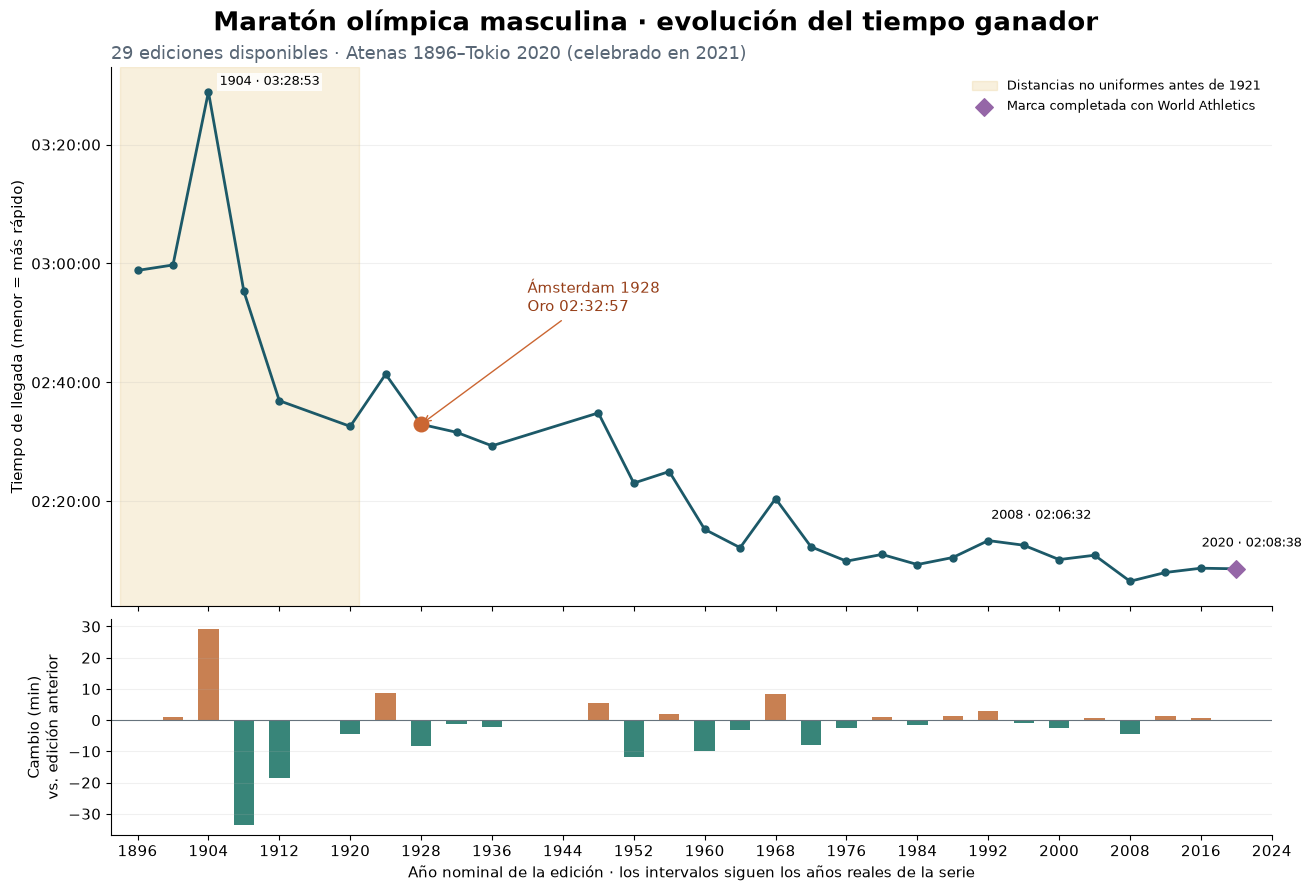

Entre 1896 y 2020, el oro pasa de 02:58:50 a 02:08:38: 50.20 minutos menos (28.1%). Desde 1924, después de la estandarización, la reducción es de 32.74 minutos (20.3%). El descenso más pronunciado entre ediciones consecutivas observadas ocurre en 1904–1908 (33.58 min); el mayor aumento, en 1900–1904 (29.13 min). La marca de oro más rápida de esta copia es 02:06:32 en 2008. La trayectoria mejora a largo plazo, pero no de forma monótona: las oscilaciones impiden interpretar cada década como un progreso uniforme. Las distancias previas a 1921 limitan la comparación inicial; recorrido, clima y altitud también son factores plausibles, pero no están medidos aquí. No se puede atribuir un salto a nutrición o tecnología sin evidencia adicional y controles de contexto. Son tiempos de campeones olímpicos, no una serie de récords mundiales ni del corredor promedio.


865

In [12]:
tablas = cargar_datos()
maraton, _, _, _ = limpiar_maraton(tablas)
podios = extraer_podios(maraton, tablas["medals"], BASE / "datos_documentales/suplemento_tokio2020.csv")
oros, conclusion_evolucion = analizar_evolucion(podios)
oros[["Año", "Tiempo", "Cambio segundos", "Edición anterior"]].to_csv(SALIDA / "evolucion_oro.csv", index=False)
figura_evolucion = graficar_evolucion(podios)
plt.show()
plt.close(figura_evolucion)
print(conclusion_evolucion)
(SALIDA / "conclusion_evolucion.txt").write_text(conclusion_evolucion, encoding="utf-8")

**Interpretación histórica del gráfico.** El oro pasa de **02:58:50 en 1896 a
02:08:38 en Tokio 2020**: 50,20 minutos menos, una reducción aproximada del 28,1 %.
Desde 1924, la reducción es de 32,74 minutos (20,3 %). La diferencia entre ambos
porcentajes muestra por qué no conviene ignorar la falta de uniformidad inicial.

Los mayores cambios consecutivos se concentran alrededor de 1904: el tiempo
aumenta 29,13 minutos desde 1900 y disminuye 33,58 minutos hasta 1908. La marca
de oro más rápida de esta copia corresponde a 2008, con 02:06:32. También existen
retrocesos posteriores, por lo que la evolución no es monótona. Recorrido, clima,
altitud, preparación o equipamiento son posibles factores de contexto, pero esta
serie no mide sus efectos y no permite atribuirles causalmente una variación.


[Volver al índice](#indice-contenidos)

# **SECCIÓN II · Profundización histórica: Manuel Plaza en Ámsterdam 1928**

<a id="tarea-4"></a>
## **4. Podio de 1928 y diferencia exacta respecto del oro**

El análisis cambia de escala: a partir del mismo podio histórico se selecciona Ámsterdam 1928. La finalidad es comprobar la clasificación y expresar con precisión la diferencia que después se integrará a la narración.

### 4.1. Identificación del caso de estudio y cálculo de la brecha

`analizar_1928()` filtra por la clave `amsterdam-1928` y ordena las tres filas
por puesto. Antes de restar tiempos comprueba que el podio esté completo, que se
identifique un único Manuel Plaza y que su medalla sea de plata. Si faltara una
marca, el cálculo se detendría para evitar una diferencia incompleta.

El tiempo del ganador se resta del tiempo de cada medallista y se guarda en
`Diferencia oro segundos`. Los nombres y países de presentación se añaden en
columnas independientes; de ese modo la tabla mantiene también las etiquetas
originales. Se devuelve el podio completo y `df_stats`, que contiene la fila de
Plaza para la función narrativa de la tarea 7.


In [13]:
import pandas as pd

def analizar_1928(podios):
    podio = podios.loc[podios["slug_game"].eq("amsterdam-1928")].sort_values("Puesto").copy()
    if len(podio) != 3 or set(podio["Puesto"]) != {1, 2, 3}:
        raise ValueError("No hay un podio completo para Ámsterdam 1928")
    plaza = podio.loc[podio["Atleta"].str.contains("Manuel.*PLAZA", case=False, regex=True, na=False)]
    if len(plaza) != 1 or plaza.iloc[0]["Medalla"] != "Plata":
        raise ValueError("No se identifica de forma unívoca la plata de Manuel Plaza")
    if podio["Tiempo segundos"].isna().any():
        raise ValueError("Faltan marcas para calcular la diferencia")
    oro = float(podio.loc[podio["Puesto"].eq(1), "Tiempo segundos"].iloc[0])
    podio["Diferencia oro segundos"] = podio["Tiempo segundos"] - oro
    if podio["Diferencia oro segundos"].lt(0).any():
        raise ValueError("Hay marcas inconsistentes con el orden de 1928")
    nombres = {1: "Boughera El Ouafi", 2: "Manuel Plaza Reyes", 3: "Martti Marttelin"}
    paises = {1: "Francia", 2: "Chile", 3: "Finlandia"}
    podio["Atleta presentación"] = podio["Puesto"].map(nombres)
    podio["País presentación"] = podio["Puesto"].map(paises)
    estadisticas = podio.loc[podio["Puesto"].eq(2)].copy()
    return podio, estadisticas

### 4.2. Presentación e interpretación del podio de Ámsterdam

La tabla siguiente muestra las tres medallas, los nombres legibles, el país,
el tiempo y la diferencia frente al oro. La operación de interés se verifica
directamente en segundos: **9203 − 9177 = 26**. No es necesario redondear ni
aproximar una resta de cadenas de texto.

Se exportan tanto el podio como la observación estadística de Plaza. Al utilizar
objetos provenientes de la misma serie histórica, se evita transcribir manualmente
una segunda versión de los números que podría divergir de los resultados del análisis.


In [14]:
tablas = cargar_datos()
maraton, _, _, _ = limpiar_maraton(tablas)
podios = extraer_podios(maraton, tablas["medals"], BASE / "datos_documentales/suplemento_tokio2020.csv")
podio_1928, df_stats = analizar_1928(podios)
columnas_1928 = ["Medalla", "Atleta presentación", "País presentación", "Tiempo", "Diferencia oro segundos"]
mostrar_tabla(podio_1928[columnas_1928])
print(f"\nManuel Plaza quedó a {df_stats.iloc[0]['Diferencia oro segundos']:g} segundos del oro.")
podio_1928.to_csv(SALIDA / "podio_1928.csv", index=False)
df_stats.to_csv(SALIDA / "estadisticas_plaza.csv", index=False)

,Medalla,Atleta presentación,País presentación,Tiempo,Diferencia oro segundos
21,Oro,Boughera El Ouafi,Francia,02:32:57,0.0
22,Plata,Manuel Plaza Reyes,Chile,02:33:23,26.0
23,Bronce,Martti Marttelin,Finlandia,02:35:02,125.0



Manuel Plaza quedó a 26 segundos del oro.


**Interpretación del caso.** Boughera El Ouafi registra **02:32:57**, Manuel
Plaza **02:33:23** y Martti Marttelin **02:35:02**. Por tanto, la plata queda a
**26 segundos** del oro y el bronce a 125 segundos. Esta precisión cuantifica la
proximidad del resultado, pero no demuestra un extravío ni permite afirmar qué
habría ocurrido bajo otras condiciones.

La plata figura también en el
[registro del Comité Olímpico de Chile](https://www.coch.cl/wp-content/uploads/2018/01/medallistas-olimpicos5.pdf).
La tarea siguiente incorpora contexto documental para ampliar la interpretación
sin utilizar la brecha temporal como explicación de la biografía del atleta.


[Volver al índice](#indice-contenidos)

<a id="tarea-5"></a>
## **5. Simulación de integración con fuentes documentales**

Una tabla de resultados no describe por sí sola el trabajo cotidiano ni los espacios de entrenamiento de Plaza. Se diseña una integración documental que conserva la procedencia de los textos y distingue lo simulado de las paráfrasis de fuentes consultadas.

### 5.1. Metadatos, consultas y respuesta simulada

`simular_ingesta_documental(atleta, anio, ciudad)` recibe los metadatos del caso
y construye consultas con el nombre, el año, la ciudad y términos de contexto.
`urlencode()` convierte esas consultas a una URL de búsqueda válida, pero la
función no envía solicitudes ni afirma haber recuperado noticias por internet.
La validación restringe esta caché didáctica a Manuel Plaza en Ámsterdam 1928.

La respuesta contiene tres recreaciones que permiten ensayar el procesamiento
de texto. Cada una incluye identificador, tipo documental, autor y texto; no se
le atribuye un periódico histórico ni una fecha de publicación ficticia. Los
campos semánticos se introducen deliberadamente para demostrar el análisis
léxico, lo que debe considerarse al interpretar sus conteos.


In [15]:
import hashlib

import json

from urllib.parse import urlencode

import pandas as pd

def simular_ingesta_documental(atleta, anio, ciudad):
    """Construye consultas y devuelve tres textos didácticos, nunca prensa real."""
    nombre = normalizar_texto(atleta)
    if nombre not in {"manuel plaza", "manuel plaza reyes"} or int(anio) != 1928 or normalizar_texto(ciudad) != "amsterdam":
        raise ValueError("La caché de demostración solo cubre Manuel Plaza, Ámsterdam 1928")
    consultas = [
        f'"{atleta}" "{anio}" "{ciudad}" maratón',
        f'"{atleta}" suplementero "Santiago" "Parque Cousiño"',
        f'"{atleta}" "1928" site:memoriachilena.gob.cl',
    ]
    textos = [
        f"Santiago, {anio}. {atleta}, suplementero de origen humilde, recorre la ciudad "
        "vendiendo diarios. En el Parque Cousiño entrena con esfuerzo, pese a la "
        "escasez de recursos y a la precariedad de su preparación.",
        f"Ámsterdam, 5 de agosto de {anio}. {atleta} obtiene la plata para Chile. "
        "Boughera El Ouafi representa a Francia y Martti Marttelin a Finlandia. "
        "La hazaña despierta asombro y sorpresa; Sudamérica celebra con orgullo "
        "el coraje del corredor.",
        f"El regreso de {atleta} a Santiago se narra como una gesta de esfuerzo y gloria. "
        "Su oficio de suplementero y las dificultades económicas conviven con "
        "el entusiasmo deportivo. El Parque Cousiño aparece como escenario de "
        "un entrenamiento sin recursos suficientes.",
    ]
    documentos = []
    for i, texto in enumerate(textos, 1):
        documentos.append({
            "doc_id": f"SIM_{i:02d}", "tipo_documento": "simulado",
            "titulo": f"Recreación didáctica {i} (NO es un periódico histórico)",
            "autor": "Elaboración propia para el ejercicio",
            "fuente_url": None, "fecha_publicacion": None, "anio_referido": int(anio),
            "es_cita_literal": False, "texto": texto,
        })
    plan = [{"consulta": q, "url_busqueda_conceptual": "https://www.google.com/search?" + urlencode({"q": q}),
             "estado": "simulación; consulta NO ejecutada por esta función"} for q in consultas]
    return documentos, plan

### 5.2. Incorporación de paráfrasis y trazabilidad del corpus

`preparar_corpus()` combina las recreaciones con dos paráfrasis guardadas en
`corpus_documental.json`. Una procede del reportaje de Magdalena Llanos en
[Vergara 240 / UDP](https://vergara240.udp.cl/en-busca-de-la-medalla-olimpica-perdida/)
y otra del registro institucional de medallistas. Los documentos conservan URL,
fecha de consulta y tipo; una paráfrasis es una redacción propia, no una cita literal.

La función comprueba identificadores y huellas de texto para evitar duplicados.
Además, exige una URL para cada paráfrasis documental. En un pipeline conectado,
estos controles acompañarían la descarga, la limpieza de HTML u OCR y la revisión
manual. Aquí la copia local permite ejecutar siempre el mismo corpus.


In [16]:
def preparar_corpus(atleta="Manuel Plaza Reyes", anio=1928, ciudad="Ámsterdam"):
    simulados, plan = simular_ingesta_documental(atleta, anio, ciudad)
    ruta = BASE / "datos_documentales/corpus_documental.json"
    documentales = json.loads(ruta.read_text(encoding="utf-8"))
    documentos = simulados + documentales
    ids, huellas = set(), set()
    for doc in documentos:
        if doc["tipo_documento"] not in {"simulado", "parafrasis_documental"}:
            raise ValueError("Tipo documental desconocido")
        if doc["tipo_documento"] == "parafrasis_documental" and not doc["fuente_url"]:
            raise ValueError("Falta URL para una paráfrasis documental")
        huella = hashlib.sha256(doc["texto"].encode("utf-8")).hexdigest()
        if doc["doc_id"] in ids or huella in huellas:
            raise ValueError("Documento o texto duplicado")
        ids.add(doc["doc_id"])
        huellas.add(huella)
        doc["sha256_texto"] = huella
    return documentos, pd.DataFrame(plan)

### 5.3. Revisión de las consultas y de los textos utilizados

Se muestran el plan de búsqueda y cada documento con su identificador y tipo.
Esta revisión hace visible qué material entrará al NLP, antes de reducirlo a
tokens o entidades. El corpus utilizado se guarda en JSON y el plan en CSV para
conservar la relación entre el diseño de integración y la entrada real del análisis.

La clasificación documental no se descarta después de la lectura: se trasladará
a las tablas de entidades y tono. Así será posible comparar tipos de texto y
evitar que una recreación termine respaldando una afirmación histórica.


In [17]:
corpus, plan_busqueda = preparar_corpus()
(SALIDA / "corpus_utilizado.json").write_text(json.dumps(corpus, ensure_ascii=False, indent=2), encoding="utf-8")
plan_busqueda.to_csv(SALIDA / "plan_busqueda.csv", index=False)
mostrar_tabla(plan_busqueda[["consulta", "estado"]])
for documento in corpus:
    print(f"\n[{documento['doc_id']} · {documento['tipo_documento']}]\n{documento['texto']}")

,consulta,estado
0,"""Manuel Plaza Reyes"" ""1928"" ""Ámsterdam"" maratón",simulación; consulta NO ejecutada por esta fun...
1,"""Manuel Plaza Reyes"" suplementero ""Santiago"" ""...",simulación; consulta NO ejecutada por esta fun...
2,"""Manuel Plaza Reyes"" ""1928"" site:memoriachilen...",simulación; consulta NO ejecutada por esta fun...



[SIM_01 · simulado]
Santiago, 1928. Manuel Plaza Reyes, suplementero de origen humilde, recorre la ciudad vendiendo diarios. En el Parque Cousiño entrena con esfuerzo, pese a la escasez de recursos y a la precariedad de su preparación.

[SIM_02 · simulado]
Ámsterdam, 5 de agosto de 1928. Manuel Plaza Reyes obtiene la plata para Chile. Boughera El Ouafi representa a Francia y Martti Marttelin a Finlandia. La hazaña despierta asombro y sorpresa; Sudamérica celebra con orgullo el coraje del corredor.

[SIM_03 · simulado]
El regreso de Manuel Plaza Reyes a Santiago se narra como una gesta de esfuerzo y gloria. Su oficio de suplementero y las dificultades económicas conviven con el entusiasmo deportivo. El Parque Cousiño aparece como escenario de un entrenamiento sin recursos suficientes.

[DOC_UDP · parafrasis_documental]
La investigación de Magdalena Llanos en Vergara 240 describe a Manuel Plaza Reyes como suplementero en Santiago y sitúa sus entrenamientos en el Parque Cousiño. Vincula 

**Interpretación del corpus.** La entrada contiene **cinco documentos**:
tres simulaciones y dos paráfrasis documentales. Son suficientes para demostrar
el método, pero no constituyen una muestra representativa de periódicos de 1928.
El reportaje de UDP es retrospectivo: su información contextual debe distinguirse
de un testimonio publicado durante la competencia. La búsqueda documental añade
contexto y preguntas de investigación; no elimina por sí sola los vacíos del archivo.


[Volver al índice](#indice-contenidos)

<a id="tarea-6"></a>
## **6. Procesamiento de lenguaje natural sobre las crónicas**

El NLP organiza el contenido del mini-corpus en palabras, entidades y evidencias léxicas. Se conservan dos recorridos: el reconocimiento de entidades utiliza el texto con mayúsculas y tildes; las frecuencias utilizan tokens en minúsculas y stopwords filtradas. El análisis describe estos documentos y no generaliza a toda la prensa histórica.

### 6.1. Limpieza del texto sin destruir nombres propios

`limpiar_texto()` normaliza Unicode a NFC, retira etiquetas HTML y reúne
espacios repetidos. La limpieza es deliberadamente suave: conserva letras con
tilde, números, mayúsculas y puntuación útil para reconocer nombres, fechas y
límites de oración. Eliminar esos rasgos antes del NER podría fragmentar o
desfigurar entidades como Ámsterdam y Parque Cousiño.

`Counter` se utilizará después para frecuencias y spaCy para tokenización y
stopwords en español. No se eliminan palabras todavía: esta función produce una
versión limpia del texto que seguirá disponible para revisar los resultados.


In [18]:
from collections import Counter

import json

import re

import unicodedata

import pandas as pd

import spacy

import matplotlib.pyplot as plt

def limpiar_texto(texto):
    """Limpieza suave: Unicode, etiquetas y espacios; no destruye las entidades."""
    texto = unicodedata.normalize("NFC", texto)
    texto = re.sub(r"<[^>]+>", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

### 6.2. Tokenizador español y reconocimiento de entidades

`spacy.blank("es")` crea un procesador de español sin un modelo estadístico
preentrenado. `sentencizer` divide oraciones y `EntityRuler` aplica un catálogo de
patrones de dominio. La comparación LOWER tolera cambios de mayúsculas; no
equivale a corregir errores de OCR ni a reconocer cualquier nombre desconocido.

Las etiquetas PER, LOC, DATE y ORG representan personas, lugares, fechas y
organizaciones. OCUPACION es una etiqueta propia que permite conservar el oficio
de suplementero como contexto. Se añaden patrones para años y fechas completas;
si coinciden, spaCy resuelve los solapamientos de las entidades.

Se trata de NER mediante reglas explícitas. Su ventaja aquí es la reproducibilidad
y la posibilidad de auditar cada patrón; su límite es la dependencia del vocabulario
declarado. La presencia de una entidad señala una mención, no verifica que toda
la oración que la rodea sea históricamente cierta.


In [19]:
def crear_pipeline_nlp():
    nlp = spacy.blank("es")
    nlp.add_pipe("sentencizer")
    ruler = nlp.add_pipe("entity_ruler", config={"phrase_matcher_attr": "LOWER"})
    catalogo = {
        "PER": ["Manuel Plaza Reyes", "Manuel Plaza", "Boughera El Ouafi", "Martti Marttelin", "Magdalena Llanos", "Alfonso Sánchez Rodríguez"],
        "LOC": ["Ámsterdam", "Amsterdam", "Santiago", "Parque Cousiño", "Sudamérica", "Chile", "Francia", "Finlandia"],
        "ORG": ["Vergara 240", "Comité Olímpico de Chile"],
        "OCUPACION": ["suplementero", "suplementeros"],
    }
    patrones = [{"label": etiqueta, "pattern": nombre} for etiqueta, nombres in catalogo.items() for nombre in nombres]
    patrones += [
        {"label": "DATE", "pattern": [{"TEXT": {"REGEX": r"^(?:18|19|20)\d{2}$"}}]},
        {"label": "DATE", "pattern": [{"TEXT": {"REGEX": r"^\d{1,2}$"}}, {"LOWER": "de"},
                                             {"LOWER": {"IN": ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]}},
                                             {"LOWER": "de"}, {"TEXT": {"REGEX": r"^(?:18|19|20)\d{2}$"}}]},
    ]
    ruler.add_patterns(patrones)
    return nlp

### 6.3. Campos semánticos, tasas y tratamiento de negaciones

`LEXICO` define tres campos: épica, sorpresa y precariedad. La función recorre
los tokens alfabéticos de cada oración y cuenta coincidencias exactas, por lo que
no incorpora automáticamente sinónimos, flexiones o sentidos implícitos. Un texto
puede contener varios campos; el tono predominante admite empates.

Para comparar longitudes se calcula **tasa = coincidencias ÷ tokens alfabéticos × 100**.
El denominador corresponde al texto previo al filtrado de stopwords. Además,
la ventana de tres tokens anteriores busca negaciones dentro de la misma oración;
las coincidencias negadas se guardan como evidencia, pero no incrementan el campo.

Este procedimiento es un análisis léxico exploratorio, no un clasificador validado
de sentimiento. Una alusión a dificultades económicas tampoco expresa por sí
misma una valoración negativa del atleta. Guardar la oración permite revisar
posibles falsos positivos y negaciones que la regla no interprete correctamente.


In [20]:
LEXICO = {
    "epica": {"hazaña", "gesta", "gloria", "orgullo", "coraje", "heroico", "heroica", "proeza", "esfuerzo", "entusiasmo"},
    "sorpresa": {"asombro", "sorpresa", "inesperado", "inesperada", "sorprendente"},
    "precariedad": {"humilde", "escasez", "precariedad", "dificultades", "pobreza", "limitados"},
}

NEGACIONES = {"no", "nunca", "jamás", "jamas", "sin"}

def analizar_lexico(doc):
    conteos = dict.fromkeys(LEXICO, 0)
    evidencias = []
    for oracion in doc.sents:
        tokens = [t for t in oracion if t.is_alpha]
        for i, token in enumerate(tokens):
            for categoria, palabras in LEXICO.items():
                if token.lower_ in palabras:
                    anteriores = {t.lower_ for t in tokens[max(0, i - 3):i]}
                    negado = bool(anteriores & NEGACIONES)
                    conteos[categoria] += int(not negado)
                    evidencias.append({"categoria": categoria, "palabra": token.text,
                                       "negado": negado, "oracion": oracion.text})
    total = sum(t.is_alpha for t in doc)
    tasas = {f"{k}_por_100": round(v / total * 100, 3) if total else 0.0 for k, v in conteos.items()}
    maximo = max(conteos.values())
    tono = ", ".join(k for k, v in conteos.items() if v == maximo) if maximo else "sin evidencia léxica"
    return {"tokens_alfabeticos": total, **conteos, **tasas, "tono_predominante": tono}, evidencias

### 6.4. Aplicación del pipeline y construcción de tablas de salida

`procesar_corpus()` aplica el mismo pipeline a cada documento con `nlp.pipe()`.
Para las frecuencias conserva tokens alfabéticos en minúsculas y elimina las
stopwords españolas. Se mantienen excepciones para las negaciones, porque su
eliminación podría borrar diferencias de sentido relevantes para la interpretación.

Las entidades se guardan con identificador documental, etiqueta, posición de
inicio y fin, oración, tipo de documento y URL. Las posiciones se refieren al
texto limpio guardado, lo que permite recuperar el fragmento exacto de la mención.
Por separado se producen frecuencias, resúmenes de tono, evidencias léxicas y tokens.
Esta estructura conserva la relación entre un resultado agregado y su documento
de origen, en lugar de mezclar todos los textos en una única cadena sin procedencia.


In [21]:
def procesar_corpus(corpus):
    nlp = crear_pipeline_nlp()
    entidades, resumenes, frecuencias, coincidencias, tokenizados = [], [], [], [], []
    textos = [limpiar_texto(d["texto"]) for d in corpus]
    for documento, texto, doc in zip(corpus, textos, nlp.pipe(textos)):
        # Las negaciones se conservan para no perder contexto crítico.
        filtrados = [t.lower_ for t in doc if t.is_alpha and (not t.is_stop or t.lower_ in NEGACIONES)]
        tokenizados.append({"doc_id": documento["doc_id"], "tipo_documento": documento["tipo_documento"],
                            "texto_limpio": texto, "tokens_filtrados": filtrados})
        for palabra, n in Counter(filtrados).items():
            frecuencias.append({"doc_id": documento["doc_id"], "tipo_documento": documento["tipo_documento"], "palabra": palabra, "frecuencia": n})
        for ent in doc.ents:
            entidades.append({"doc_id": documento["doc_id"], "tipo_documento": documento["tipo_documento"],
                               "entidad": ent.text, "etiqueta": ent.label_, "inicio": ent.start_char,
                               "fin": ent.end_char, "oracion": ent.sent.text, "fuente_url": documento["fuente_url"],
                               "metodo": "spaCy EntityRuler: reglas de dominio"})
        resumen, evidencia = analizar_lexico(doc)
        resumenes.append({"doc_id": documento["doc_id"], "tipo_documento": documento["tipo_documento"],
                          "tokens_filtrados": len(filtrados), **resumen})
        coincidencias.extend({"doc_id": documento["doc_id"], **e} for e in evidencia)
    return {"entidades": pd.DataFrame(entidades), "tonos": pd.DataFrame(resumenes),
            "frecuencias": pd.DataFrame(frecuencias), "evidencias_lexicas": pd.DataFrame(coincidencias),
            "tokens": tokenizados}

### 6.5. Control de ocho entidades conocidas

Se define un pequeño control manual con ocho menciones esperadas en los
documentos simulados: personas, lugares y fechas. La comprobación usa la tupla
documento–entidad–etiqueta, de modo que encontrar Santiago en otro documento
no acredita haberlo detectado en el texto solicitado.

El resultado booleano indica si cada mención fue recuperada. Dado que el corpus
y el catálogo se diseñaron conjuntamente, este control verifica funcionamiento
en ejemplos conocidos; no mide precisión, F1 ni desempeño fuera de muestra.
Una evaluación de generalización requeriría textos y anotaciones independientes.


In [22]:
def evaluar_entidades_control(entidades):
    """Control manual de presencia; no es F1 ni evaluación fuera de muestra."""
    esperadas = [
        ("SIM_01", "Manuel Plaza Reyes", "PER"), ("SIM_01", "Santiago", "LOC"),
        ("SIM_01", "Parque Cousiño", "LOC"), ("SIM_01", "1928", "DATE"),
        ("SIM_02", "Ámsterdam", "LOC"), ("SIM_02", "5 de agosto de 1928", "DATE"),
        ("SIM_02", "Boughera El Ouafi", "PER"), ("SIM_02", "Martti Marttelin", "PER"),
    ]
    detectadas = set(entidades[["doc_id", "entidad", "etiqueta"]].itertuples(index=False, name=None))
    return pd.DataFrame([{"doc_id": d, "entidad_esperada": e, "etiqueta": t,
                          "detectada": (d, e, t) in detectadas} for d, e, t in esperadas])

### 6.6. Visualización de frecuencias y campos léxicos

El panel izquierdo agrupa por tipo documental y suma conteos y tokens antes
de calcular las tasas. Esta operación pondera correctamente por longitud: no
promedia tasas de documentos breves y largos como si tuvieran igual denominador.
Se mantienen separadas las simulaciones y las paráfrasis documentales.

El panel derecho muestra las doce palabras filtradas más frecuentes del corpus
combinado. Ese ranking permite reconocer temas y nombres recurrentes; por sí
solo no identifica emociones ni importancia histórica. La figura declara la
composición reducida del corpus para que su alcance quede visible junto al gráfico.


In [23]:
def graficar_nlp(resultados):
    tonos = resultados["tonos"]
    grupos = tonos.groupby("tipo_documento")[["epica", "sorpresa", "precariedad", "tokens_alfabeticos"]].sum()
    tasas = grupos[list(LEXICO)].div(grupos["tokens_alfabeticos"], axis=0) * 100
    frec = resultados["frecuencias"].groupby("palabra")["frecuencia"].sum().nlargest(12).sort_values()
    with plt.rc_context({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False}):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
        tasas.rename(index={"simulado": "Simulación", "parafrasis_documental": "Paráfrasis documentales"}).plot.bar(
            ax=axes[0], color=["#1c5968", "#d8a14a", "#aa6250"], rot=0)
        axes[0].set_title("Campos léxicos por tipo de texto", fontweight="bold")
        axes[0].set_ylabel("Coincidencias por 100 tokens alfabéticos")
        axes[0].set_xlabel("")
        axes[0].legend(title="Campo semántico", frameon=False)
        frec.plot.barh(ax=axes[1], color="#388579")
        axes[1].set_title("12 palabras frecuentes · corpus combinado", fontweight="bold")
        axes[1].set_xlabel("Frecuencia tras filtrar stopwords")
        axes[1].set_ylabel("")
        fig.suptitle("NLP exploratorio · 3 recreaciones y 2 paráfrasis, sin representatividad histórica", fontsize=13)
        fig.savefig(SALIDA / "analisis_nlp.png", dpi=180, bbox_inches="tight")
    return fig

### 6.7. Resultados del NLP y lectura crítica de las evidencias

Se prepara el corpus, se ejecuta el pipeline y se muestran tres salidas:
entidades reconocidas, tono léxico por documento y control manual. Después se
presenta el gráfico. Las tablas se exportan a CSV y los tokens a JSON para que
puedan revisarse sin volver a procesar los textos.

La lectura debe comparar primero documentos del mismo tipo y revisar las
oraciones que justifican los conteos. Una tasa igual a cero significa que el
diccionario no encontró palabras de ese campo; no demuestra que el texto carezca
de todo significado emocional o social.


,doc_id,entidad,etiqueta
0,SIM_01,Santiago,LOC
1,SIM_01,1928,DATE
2,SIM_01,Manuel Plaza Reyes,PER
3,SIM_01,suplementero,OCUPACION
4,SIM_01,Parque Cousiño,LOC
5,SIM_02,Ámsterdam,LOC
6,SIM_02,5 de agosto de 1928,DATE
7,SIM_02,Manuel Plaza Reyes,PER
8,SIM_02,Chile,LOC
9,SIM_02,Boughera El Ouafi,PER


TONO LÉXICO


,doc_id,tipo_documento,tokens_filtrados,tokens_alfabeticos,epica,sorpresa,precariedad,epica_por_100,sorpresa_por_100,precariedad_por_100,tono_predominante
0,SIM_01,simulado,20,33,1,0,3,3.030,0.000,9.091,precariedad
1,SIM_02,simulado,24,37,3,2,0,8.108,5.405,0.000,epica
2,SIM_03,simulado,24,42,4,0,1,9.524,0.000,2.381,epica
3,DOC_UDP,parafrasis_documental,35,61,0,0,1,0.000,0.000,1.639,precariedad
4,DOC_COCH,parafrasis_documental,19,35,0,0,0,0.000,0.000,0.000,sin evidencia léxica


CONTROL NER


,doc_id,entidad_esperada,etiqueta,detectada
0,SIM_01,Manuel Plaza Reyes,PER,True
1,SIM_01,Santiago,LOC,True
2,SIM_01,Parque Cousiño,LOC,True
3,SIM_01,1928,DATE,True
4,SIM_02,Ámsterdam,LOC,True
5,SIM_02,5 de agosto de 1928,DATE,True
6,SIM_02,Boughera El Ouafi,PER,True
7,SIM_02,Martti Marttelin,PER,True


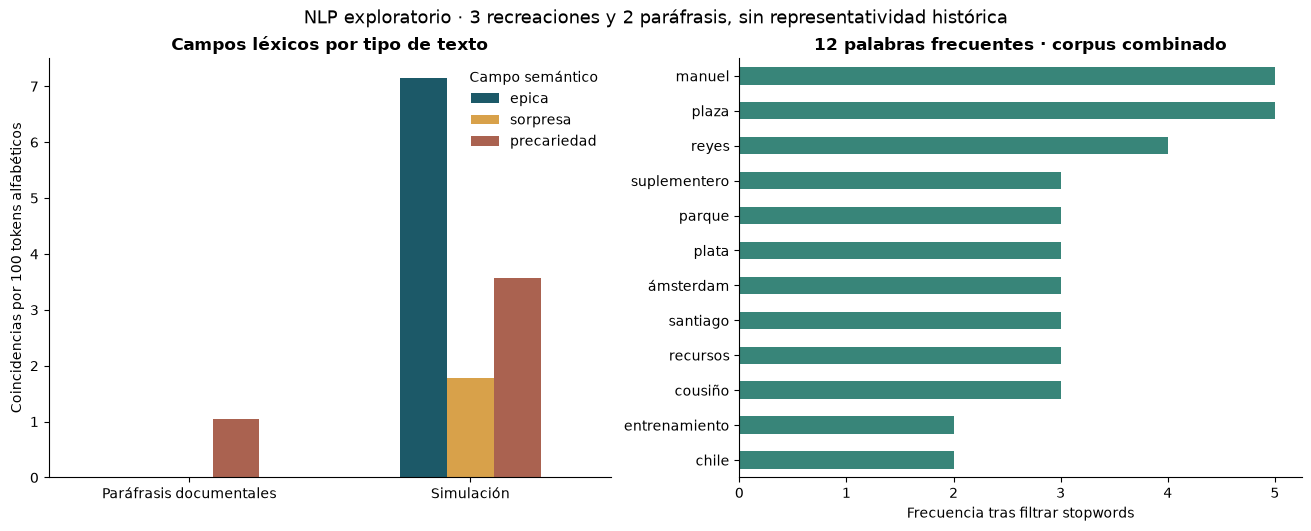

In [24]:
corpus, _ = preparar_corpus()
resultados_nlp = procesar_corpus(corpus)
entidades_nlp = resultados_nlp["entidades"]
control_ner = evaluar_entidades_control(entidades_nlp)
for nombre, tabla in resultados_nlp.items():
    if isinstance(tabla, pd.DataFrame):
        tabla.to_csv(SALIDA / f"nlp_{nombre}.csv", index=False)
(SALIDA / "nlp_tokens.json").write_text(json.dumps(resultados_nlp["tokens"], ensure_ascii=False, indent=2), encoding="utf-8")
control_ner.to_csv(SALIDA / "nlp_control_entidades.csv", index=False)
mostrar_tabla(entidades_nlp[["doc_id", "entidad", "etiqueta"]])
print("TONO LÉXICO")
mostrar_tabla(resultados_nlp["tonos"])
print("CONTROL NER")
mostrar_tabla(control_ner)
figura_nlp = graficar_nlp(resultados_nlp)
plt.show()
plt.close(figura_nlp)

**Interpretación de los resultados del NLP.** El control recupera las **ocho
entidades esperadas**, incluidas Ámsterdam, Santiago, Parque Cousiño, las personas
del podio y la fecha completa. Esto confirma el comportamiento previsto de las
reglas en el corpus construido, sin acreditar generalización.

En las tres recreaciones aparecen 8 coincidencias de épica, 2 de sorpresa y 4 de
precariedad. SIM_01 concentra vocabulario de precariedad y SIM_02 y SIM_03 de
épica; esa diferencia responde en parte al diseño didáctico de los fragmentos.
La paráfrasis de UDP aporta una coincidencia de precariedad; la del registro
institucional no presenta coincidencias en estos campos. Esa ausencia refleja
también el carácter informativo y el vocabulario de la paráfrasis.

Los conteos permiten describir esta entrada y orientar una lectura, pero no
demuestran cómo narró el logro la prensa de 1928. Para esa pregunta se necesitan
originales, un muestreo definido, revisión del OCR y validación humana del lenguaje.


[Volver al índice](#indice-contenidos)

<a id="tarea-7"></a>
## **7. Síntesis automatizada: de los datos a la crónica**

La síntesis reúne los valores calculados con el contexto organizado por NLP. Se implementa una plantilla verificable: las cifras dependen del DataFrame y las afirmaciones sociales dependen de entidades procedentes de paráfrasis documentales identificadas.

### 7.1. Diseño y validaciones de generar_cronica_historica

La función recibe `df_stats` y `entidades_nlp`. Primero comprueba columnas,
identidad del atleta, edición, ciudad, medalla y magnitudes numéricas. El tiempo
de Plaza y su diferencia frente al ganador se extraen de la fila seleccionada;
el tiempo del oro se expresa como tiempo de Plaza menos diferencia. No se escribe
26 como una constante para fabricar la brecha.

Para el contexto se conservan solo entidades con tipo `parafrasis_documental`,
URL y un documento que mencione al atleta. Si esas evidencias permiten identificar
el oficio y los lugares, la plantilla añade las frases contextuales. Si no existen,
declara que el contexto es insuficiente. Este filtro evita usar la simulación como
respaldo documental, aunque el texto simulado contenga las mismas palabras.

La generación es determinista y no llama a un modelo de lenguaje. Esa decisión
permite inspeccionar cómo cada entrada afecta a la salida; la presencia de una
entidad sigue requiriendo revisión de la oración y de su fuente para validar
relaciones históricas más complejas.


In [25]:
import numpy as np

import pandas as pd

def generar_cronica_historica(df_stats, entidades_nlp):
    """Integra cifras y entidades documentadas del caso Plaza sin inventar hechos."""
    requeridas = {"Atleta", "Año", "Ciudad", "Medalla", "Tiempo segundos", "Diferencia oro segundos"}
    if not isinstance(df_stats, pd.DataFrame) or not requeridas.issubset(df_stats.columns):
        raise ValueError(f"df_stats debe contener {sorted(requeridas)}")
    seleccion = df_stats.loc[df_stats["Atleta"].map(normalizar_texto).str.contains(r"manuel.*plaza", regex=True)
                             & df_stats["Año"].eq(1928)]
    if len(seleccion) != 1:
        raise ValueError("Se requiere una única observación de Manuel Plaza en 1928")
    fila = seleccion.iloc[0]
    tiempo, diferencia = float(fila["Tiempo segundos"]), float(fila["Diferencia oro segundos"])
    if not np.isfinite([tiempo, diferencia]).all() or tiempo <= 0 or diferencia < 0 or diferencia >= tiempo:
        raise ValueError("Tiempo o diferencia inválidos")
    if fila["Medalla"] != "Plata" or normalizar_texto(fila["Ciudad"]) != "amsterdam":
        raise ValueError("Los metadatos no corresponden al caso de estudio")
    columnas_ent = {"entidad", "etiqueta", "tipo_documento", "fuente_url", "oracion"}
    if not isinstance(entidades_nlp, pd.DataFrame) or not columnas_ent.issubset(entidades_nlp.columns):
        raise ValueError("Se requieren entidades NLP con tipo documental y procedencia")
    documentadas = entidades_nlp.loc[entidades_nlp["tipo_documento"].eq("parafrasis_documental")
                                    & entidades_nlp["fuente_url"].notna()].copy()
    entidad_norm = documentadas["entidad"].map(normalizar_texto)
    def presente(nombre, etiqueta):
        return bool((entidad_norm.eq(normalizar_texto(nombre)) & documentadas["etiqueta"].eq(etiqueta)).any())
    # Requerimos que cada contexto provenga de un documento que nombra al atleta.
    ids_atleta = set(documentadas.loc[entidad_norm.isin(["manuel plaza", "manuel plaza reyes"]), "doc_id"]) if "doc_id" in documentadas else set()
    if ids_atleta:
        documentadas = documentadas.loc[documentadas["doc_id"].isin(ids_atleta)]
        entidad_norm = documentadas["entidad"].map(normalizar_texto)
    else:
        documentadas = documentadas.iloc[0:0]
        entidad_norm = documentadas["entidad"].map(normalizar_texto)
    cronica = (
        f"En Ámsterdam {int(fila['Año'])}, Manuel Plaza Reyes, representante de Chile, "
        f"obtuvo la medalla de {fila['Medalla'].lower()} de la maratón con "
        f"{formatear_tiempo(tiempo)} ({tiempo:g} segundos). El oro se resolvió en "
        f"{formatear_tiempo(tiempo - diferencia)}: la separación exacta fue de {diferencia:g} segundos."
    )
    contextos = []
    if presente("suplementero", "OCUPACION") and presente("Santiago", "LOC"):
        contextos.append("Las fuentes documentales lo sitúan trabajando como suplementero en Santiago")
    if presente("Parque Cousiño", "LOC"):
        contextos.append("vinculan su preparación con el antiguo Parque Cousiño")
    if contextos:
        cronica += "\n\n" + "; también ".join(contextos) + ". "
        cronica += "Ese contexto permite leer la distancia al oro junto a una trayectoria de trabajo y entrenamiento que la tabla de resultados no registra."
    else:
        cronica += "\n\nNo hay entidades documentales suficientes para reconstruir el contexto social; no se completan esos vacíos con la simulación."
    cronica += (
        "\n\nEl tiempo mide el resultado, pero no explica por sí solo sus causas. "
        "Las entidades fueron reconocidas con reglas y requieren revisión histórica. "
        "Los fragmentos simulados son material didáctico, no testimonios de 1928. "
        "El centenario 1928–2028 es un horizonte de memoria, no una observación futura del dataset."
    )
    urls = sorted(set(documentadas["fuente_url"].dropna()))
    if urls:
        cronica += "\n\nContexto documental: " + "; ".join(urls)
    return cronica

### 7.2. Crónica integrada y revisión de su procedencia

Se obtiene de nuevo la observación estadística de Plaza y se procesan las
entidades del mismo corpus. La función construye la crónica, la muestra y la
guarda en `cronica_historica.txt`. El primer párrafo debe coincidir con los números
de la tarea 4; los párrafos contextuales deben corresponder a la evidencia que
se mantuvo después de filtrar por tipo documental.

Esta ejecución permite revisar la integración completa: el resultado no consiste
solo en mencionar estadísticas y lugares en un mismo texto, sino en conservar
la diferencia entre cálculo, contexto documentado y simulación didáctica.


In [26]:
tablas = cargar_datos()
maraton, _, _, _ = limpiar_maraton(tablas)
podios = extraer_podios(maraton, tablas["medals"], BASE / "datos_documentales/suplemento_tokio2020.csv")
podio_1928, df_stats = analizar_1928(podios)
corpus, _ = preparar_corpus()
resultados_nlp = procesar_corpus(corpus)
entidades_nlp = resultados_nlp["entidades"]
cronica = generar_cronica_historica(df_stats, entidades_nlp)
print(cronica)
(SALIDA / "cronica_historica.txt").write_text(cronica, encoding="utf-8")

En Ámsterdam 1928, Manuel Plaza Reyes, representante de Chile, obtuvo la medalla de plata de la maratón con 02:33:23 (9203 segundos). El oro se resolvió en 02:32:57: la separación exacta fue de 26 segundos.

Las fuentes documentales lo sitúan trabajando como suplementero en Santiago; también vinculan su preparación con el antiguo Parque Cousiño. Ese contexto permite leer la distancia al oro junto a una trayectoria de trabajo y entrenamiento que la tabla de resultados no registra.

El tiempo mide el resultado, pero no explica por sí solo sus causas. Las entidades fueron reconocidas con reglas y requieren revisión histórica. Los fragmentos simulados son material didáctico, no testimonios de 1928. El centenario 1928–2028 es un horizonte de memoria, no una observación futura del dataset.

Contexto documental: https://vergara240.udp.cl/en-busca-de-la-medalla-olimpica-perdida/; https://www.coch.cl/wp-content/uploads/2018/01/medallistas-olimpicos5.pdf


958

**Interpretación de la crónica.** La salida conserva **02:33:23**, la plata y
los **26 segundos** de separación. Añade el oficio y los lugares que aparecen en
las paráfrasis documentales y presenta las URL del contexto. La narración permite
relacionar el resultado con una trayectoria humana sin convertir una diferencia
temporal en una explicación causal del desenlace.

La utilidad del procedimiento reside en que sus límites también son reproducibles:
si se retiran las entidades documentadas, la función comunica la ausencia de
contexto en vez de sustituirlas por información simulada.


[Volver al índice](#indice-contenidos)

# **SECCIÓN III · Pregunta conceptual y de cierre**

<a id="tarea-8"></a>
## **8. Reflexión crítica sobre Big Data e historia**

El cierre responde a la pregunta conceptual del enunciado con un ensayo de doce líneas. Se valora qué añade combinar tablas y textos, sin equiparar automáticamente un archivo histórico extenso en el tiempo con una infraestructura de Big Data.

### 8.1. Ensayo de cierre: el horizonte 1928–2028



[Volver al índice](#indice-contenidos)

<a id="conclusiones-integradas"></a>
## **Conclusiones integradas**

El macroanálisis reconstruye 29 podios y hace visible una mejora de largo plazo
en los tiempos ganadores, junto con oscilaciones que impiden leer la serie como
un progreso uniforme. La normalización en segundos permite medir los cambios;
la distinción de distancias históricas y de procedencia limita interpretaciones
que no podrían justificarse únicamente con los valores del gráfico.

En el caso de Plaza, la diferencia de 26 segundos es un resultado exacto del
cálculo. El contexto documental amplía las preguntas que se pueden hacer sobre
ese resultado: las menciones a un oficio y a espacios de entrenamiento aportan
dimensiones que no aparecen en la clasificación deportiva. El NLP ayuda a
organizar esas menciones y a conservar su vínculo con cada documento.

La integración aporta valor cuando permite revisar de dónde salió una cifra,
qué texto sostiene un contexto y qué parte del ejercicio fue simulada. Las reglas
de entidades, el corpus pequeño y las paráfrasis tienen un alcance exploratorio;
una investigación histórica más amplia debería trabajar con originales y una
selección documental justificada. Los resultados aquí permiten demostrar un
proceso reproducible y reconocer qué evidencia adicional sería necesaria.

[Volver al índice](#indice-contenidos)


<a id="fuentes-limites"></a>
## Fuentes y límites del trabajo

- [Kaggle: Olympic Summer & Winter Games, 1896–2022](https://www.kaggle.com/datasets/piterfm/olympic-games-medals-19862018). Se analiza la copia local de cuatro CSV; no se supone una actualización automática del dataset.
- [World Athletics: podio masculino de Tokio](https://worldathletics.org/news/report/tokyo-olympic-games-men-marathon-report). Fuente de las tres marcas complementarias, consultada el 2 de noviembre de 2026.
- [World Athletics: historia y distancia de la maratón](https://worldathletics.org/disciplines/race-walks/marathon). Contexto de la estandarización en 1921; no es una explicación causal de cada cambio observado.
- [Magdalena Llanos: En busca de la medalla olímpica perdida, Vergara 240 / UDP](https://vergara240.udp.cl/en-busca-de-la-medalla-olimpica-perdida/). [Contenido multimedia enlazado por la página](https://multimedia.vergara240.udp.cl/en-busca-de-la-medalla-ol-mpica-perdida/). Reportaje retrospectivo consultado el 2 de noviembre de 2026; fecha de publicación no confirmada. Se usan paráfrasis propias, sin presentar el reportaje como prensa de 1928.
- [Comité Olímpico de Chile: Medallistas olímpicos chilenos](https://www.coch.cl/wp-content/uploads/2018/01/medallistas-olimpicos5.pdf). Respaldo institucional de la plata; consulta del 2 de noviembre de 2026.

El mini-corpus mezcla tres recreaciones claramente identificadas y dos paráfrasis
documentales. Sirve para demostrar el pipeline; su vocabulario y su tamaño no
permiten generalizar a la prensa histórica. El NER es por reglas y su control
verifica ejemplos conocidos. La reflexión tiene doce líneas; el centenario de
2028 se discute como horizonte, sin fabricar resultados posteriores a esta copia.


[Volver al índice](#indice-contenidos)